# Livrable 3 : solutions de référence (baselines) et chaîne complète


# Partie 1 : chargement des données préparées

In [1]:
import pandas as pd

# Fichiers produits par le livrable 2 (déjà nettoyés et découpés)
train = pd.read_csv("../data/livrable2/train.csv")
val = pd.read_csv("../data/livrable2/val.csv")
# test.csv n'est PAS chargé : il reste de côté jusqu'à la séance 5 (une seule utilisation)

print(train.shape, val.shape)

(41564, 31) (8901, 31)


In [2]:
# Ce qu'on cherche à prédire
cible = "status_group"
y_train = train[cible]
y_val = val[cible]

# La classe qui nous intéresse le plus : rare (7 %) mais la plus coûteuse à rater
A_REPARER = "functional needs repair"
y_train.value_counts(normalize=True).round(3)

status_group
functional                 0.543
non functional             0.384
functional needs repair    0.073
Name: proportion, dtype: float64

# Partie 2 : baseline 0, la classe la plus fréquente

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, classification_report
import time

durees = {}   # temps d'entraînement de chaque modèle, en secondes

# Ce « modèle » ne regarde aucune variable : il répond toujours « functional »
majoritaire = DummyClassifier(strategy="most_frequent")
debut = time.perf_counter()
majoritaire.fit(train, y_train)
durees["majoritaire"] = time.perf_counter() - debut
pred = majoritaire.predict(val)

print("Accuracy :", round(accuracy_score(y_val, pred), 3))
print("Rappel à réparer :", recall_score(y_val, pred, labels=[A_REPARER], average="macro"))

Accuracy : 0.543
Rappel à réparer : 0.0


# Partie 3 : baseline 1, modèles simples sur dix variables choisies à la main

## 3.1 Les dix variables

In [4]:
# Choisies d'après l'exploration du livrable 2 (lien visible avec l'état, peu de modalités) :
categorielles = [
    "quantity",               # quantité d'eau : variable la plus liée à l'état
    "waterpoint_type",        # type de point d'eau (pompe à main, borne-fontaine...)
    "extraction_type_class",  # technique d'extraction (manuelle, motorisée, gravité...)
    "payment",                # les usagers paient-ils l'eau ? (entretien financé ou non)
    "source",                 # origine de l'eau (forage, source, rivière...)
    "water_quality",          # qualité de l'eau
    "management_group",       # qui gère le point (communauté, privé...)
    "region",                 # 21 régions : situation géographique simple
]
numeriques = [
    "age",                    # âge du point au moment du relevé
    "gps_height",             # altitude
]

# Écartées volontairement pour cette baseline :
# funder, installer, ward... : des milliers de modalités, trop pour un modèle simple
# longitude, latitude : le lieu est déjà résumé par region

# Remarque : quantity = dry donne presque toujours non functional. On la garde ici,
# mais il faut vérifier si cette information est connue sans visiter le point.

variables = categorielles + numeriques

## 3.2 Préparation des variables

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preparation = ColumnTransformer([
    # Texte -> colonnes 0/1 (une par modalité).
    # handle_unknown="ignore" : une modalité absente du train ne fait pas planter la validation
    ("texte", OneHotEncoder(handle_unknown="ignore"), categorielles),
    # Nombres remis à la même échelle (moyenne 0, écart-type 1) :
    # sinon l'altitude (en milliers) écraserait l'âge (en dizaines) dans la régression logistique
    ("nombres", StandardScaler(), numeriques),
])

## 3.3 Régression logistique

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Pipeline : la préparation est apprise sur le train seulement, puis appliquée telle quelle à val
logistique = make_pipeline(preparation, LogisticRegression(max_iter=1000))
debut = time.perf_counter()
logistique.fit(train[variables], y_train)
durees["logistique_10var"] = time.perf_counter() - debut
pred_log = logistique.predict(val[variables])

print(classification_report(y_val, pred_log, digits=3))

                         precision    recall  f1-score   support

             functional      0.704     0.915     0.796      4834
functional needs repair      0.471     0.037     0.069       646
         non functional      0.806     0.605     0.692      3421

               accuracy                          0.732      8901
              macro avg      0.660     0.519     0.519      8901
           weighted avg      0.726     0.732     0.703      8901



## 3.4 Arbre de décision

In [7]:
from sklearn.tree import DecisionTreeClassifier

# max_depth=8 : profondeur limitée pour garder un arbre lisible et éviter qu'il apprenne le train par cœur
# random_state=42 : même arbre à chaque exécution
arbre = make_pipeline(preparation, DecisionTreeClassifier(max_depth=8, random_state=42))
debut = time.perf_counter()
arbre.fit(train[variables], y_train)
durees["arbre_10var"] = time.perf_counter() - debut
pred_arbre = arbre.predict(val[variables])

print(classification_report(y_val, pred_arbre, digits=3))

                         precision    recall  f1-score   support

             functional      0.695     0.945     0.801      4834
functional needs repair      0.606     0.088     0.154       646
         non functional      0.861     0.563     0.681      3421

               accuracy                          0.736      8901
              macro avg      0.721     0.532     0.545      8901
           weighted avg      0.752     0.736     0.708      8901



## 3.5 Matrices de confusion

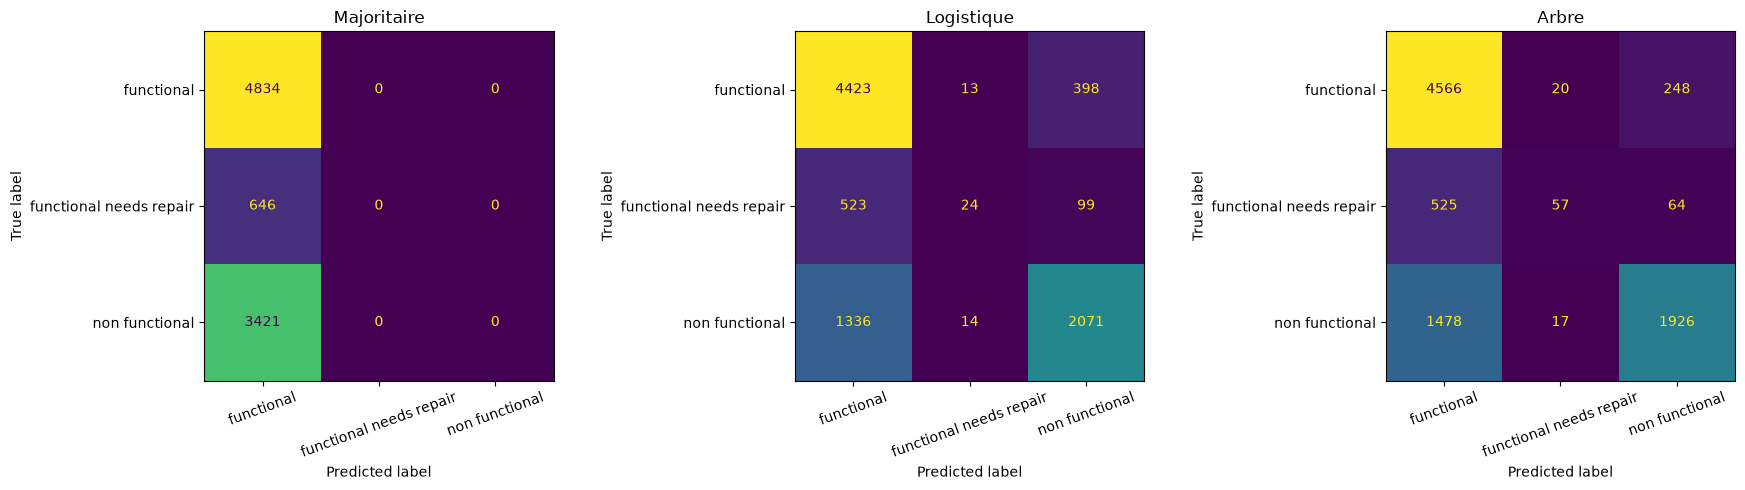

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Lignes = état réel, colonnes = état prédit. La diagonale = les bonnes réponses.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nom, p) in zip(axes, [("Majoritaire", pred), ("Logistique", pred_log), ("Arbre", pred_arbre)]):
    ConfusionMatrixDisplay.from_predictions(y_val, p, ax=ax, colorbar=False, xticks_rotation=20)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

# Partie 4 : comparaison et journal d'expériences

In [9]:
from sklearn.metrics import f1_score

predictions = {"majoritaire": pred, "logistique_10var": pred_log, "arbre_10var": pred_arbre}

resultats = pd.DataFrame({
    "modele": list(predictions),
    "exactitude_val": [accuracy_score(y_val, p) for p in predictions.values()],   # accuracy
    "rappel_a_reparer_val": [recall_score(y_val, p, labels=[A_REPARER], average="macro")
                             for p in predictions.values()],
    "f1_macro_val": [f1_score(y_val, p, average="macro") for p in predictions.values()],  # 3 classes, même poids
}).round(3)
resultats

,modele,exactitude_val,rappel_a_reparer_val,f1_macro_val
0,majoritaire,0.543,0.000,0.235
1,logistique_10var,0.732,0.037,0.519
2,arbre_10var,0.736,0.088,0.545


In [10]:
import os
import subprocess
from datetime import date

AUTEUR = "PODA"   # à changer par celui qui lance le notebook

# Numéro du commit Git en cours : permet de retrouver le code exact qui a donné ces scores
try:
    commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"],
                            capture_output=True, text=True).stdout.strip() or "sans-git"
except FileNotFoundError:
    commit = "sans-git"

observations = {
    "majoritaire": "baseline 0 : aucun point à réparer trouvé",
    "logistique_10var": "baseline 1 : rate presque toute la classe à réparer",
    "arbre_10var": "baseline 1 : un peu mieux sur la classe à réparer",
}

journal = resultats.assign(date=date.today().isoformat(), auteur=AUTEUR, commit=commit,
                           duree_s=resultats["modele"].map(durees).round(3),
                           observation=resultats["modele"].map(observations))
colonnes = ["date", "auteur", "commit", "modele", "exactitude_val", "rappel_a_reparer_val",
            "f1_macro_val", "duree_s", "observation"]
journal = journal[colonnes]

# experiments.csv : le journal demandé par la fiche.
# Même modèle et mêmes scores : la ligne est remplacée (date et durée à jour), donc pas de doublon.
# Si un score change : une nouvelle ligne s'ajoute, et l'ancienne reste comme trace.
fichier = "../experiments.csv"
memes_essais = ["modele", "exactitude_val", "rappel_a_reparer_val", "f1_macro_val"]
if os.path.exists(fichier):
    journal = pd.concat([pd.read_csv(fichier), journal]).drop_duplicates(subset=memes_essais, keep="last")
journal.to_csv(fichier, index=False)
pd.read_csv(fichier)

,date,auteur,commit,modele,exactitude_val,rappel_a_reparer_val,f1_macro_val,duree_s,observation
0,2026-11-05,PODA,ee74c7c,majoritaire,0.543,0.000,0.235,0.034,baseline 0 : aucun point à réparer trouvé
1,2026-11-05,PODA,ee74c7c,logistique_10var,0.732,0.037,0.519,1.109,baseline 1 : rate presque toute la classe à ré...
2,2026-11-05,PODA,ee74c7c,arbre_10var,0.736,0.088,0.545,0.684,baseline 1 : un peu mieux sur la classe à réparer


## Ce qu'il faut retenir

1. La baseline majoritaire donne le plancher : accuracy d'environ 0,54, rappel nul sur la classe à réparer.
2. Les modèles simples gagnent près de 20 points d'accuracy, mais trouvent très peu de points à réparer.

# Partie 5 : schéma de la chaîne complète

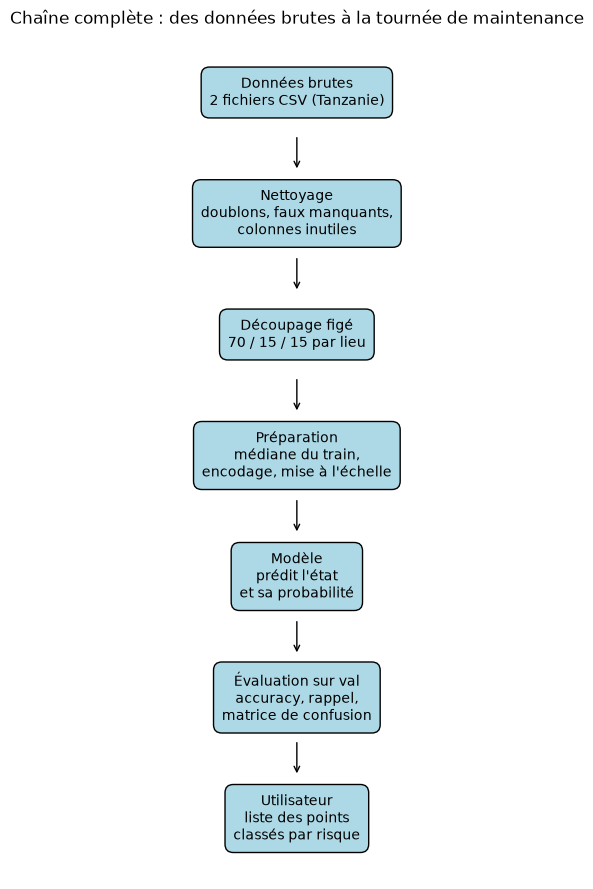

In [11]:
etapes = [
    "Données brutes\n2 fichiers CSV (Tanzanie)",
    "Nettoyage\ndoublons, faux manquants,\ncolonnes inutiles",
    "Découpage figé\n70 / 15 / 15 par lieu",
    "Préparation\nmédiane du train,\nencodage, mise à l'échelle",
    "Modèle\nprédit l'état\net sa probabilité",
    "Évaluation sur val\naccuracy, rappel,\nmatrice de confusion",
    "Utilisateur\nliste des points\nclassés par risque",
]

# Une boîte par étape, de haut en bas, reliées par des flèches
fig, ax = plt.subplots(figsize=(6, 11))
for i, texte in enumerate(etapes):
    y = -i * 2
    ax.text(0, y, texte, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round", facecolor="lightblue", pad=0.6))
    if i < len(etapes) - 1:
        ax.annotate("", xy=(0, y - 1.3), xytext=(0, y - 0.7), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-2, 2)
ax.set_ylim(-(len(etapes) - 1) * 2 - 1, 1)
ax.axis("off")
plt.title("Chaîne complète : des données brutes à la tournée de maintenance")
plt.show()

# Partie 6 : enregistrement des modèles

In [12]:
import joblib

# Dossier à part : les anciens fichiers de outputs/ datent d'avant le découpage du livrable 2
dossier = "../outputs/livrable3"
os.makedirs(dossier, exist_ok=True)

modeles = {"majoritaire": majoritaire, "logistique_10var": logistique, "arbre_10var": arbre}
for nom, modele in modeles.items():
    joblib.dump(modele, f"{dossier}/{nom}.joblib")
    print(nom, ":", round(os.path.getsize(f"{dossier}/{nom}.joblib") / 1024), "Ko")

# Vérification : le modèle relu depuis le fichier doit répondre exactement la même chose
arbre_relu = joblib.load(f"{dossier}/arbre_10var.joblib")
print("Mêmes prédictions après relecture :", (arbre_relu.predict(val[variables]) == pred_arbre).all())

majoritaire : 1 Ko
logistique_10var : 7 Ko
arbre_10var : 36 Ko
Mêmes prédictions après relecture : True


# Partie 7 : analyse de 10 erreurs du meilleur modèle

Meilleur modèle sur la validation : l'**arbre** (F1 macro 0,545 et rappel « à réparer » 0,088 contre 0,519 et 0,037 pour la logistique).



## 7.1 Où l'arbre se trompe-t-il ?

In [13]:
# Lignes = état réel, colonnes = état prédit
print(pd.crosstab(y_val, pred_arbre, rownames=["réel"], colnames=["prédit"]))

erreurs = val[y_val != pred_arbre]
print("\nErreurs :", len(erreurs), "sur", len(val))
print("Points à réparer vus comme fonctionnels :",
      round(((y_val == A_REPARER) & (pred_arbre == "functional")).sum() / (y_val == A_REPARER).sum(), 3))

prédit                   functional  functional needs repair  non functional
réel                                                                        
functional                     4566                       20             248
functional needs repair         525                       57              64
non functional                 1478                       17            1926

Erreurs : 2352 sur 8901
Points à réparer vus comme fonctionnels : 0.813


## 7.2 Choix des 10 erreurs

Explication des choix:

- 5 points **à réparer** prédits fonctionnels  ;
- 3 points **hors service** prédits fonctionnels  ;
- 2 points **fonctionnels** prédits hors service .


In [14]:
# Probabilité donnée par l'arbre à sa réponse
probas = pd.DataFrame(arbre.predict_proba(val[variables]), columns=arbre.classes_, index=val.index)

tableau = val[["id"] + variables].copy()
tableau["reel"] = y_val
tableau["predit"] = pred_arbre
tableau["proba"] = probas.max(axis=1).round(3)

choix = [(A_REPARER, "functional", 5), ("non functional", "functional", 3), ("functional", "non functional", 2)]
morceaux = []
for reel, predit, nombre in choix:
    cas = tableau[(tableau["reel"] == reel) & (tableau["predit"] == predit)]
    # À probabilité égale, le plus petit id passe d'abord : le choix est toujours le même
    morceaux.append(cas.sort_values(["proba", "id"], ascending=[False, True]).head(nombre))
dix = pd.concat(morceaux)
dix.T

,5380,6973,1121,8817,6670,5414,8180,7693,3763,6375
id,22034,46690,57459,18738,23965,5278,41822,49544,3239,19509
quantity,enough,enough,enough,enough,enough,dry,dry,insufficient,dry,dry
waterpoint_type,communal standpipe multiple,communal standpipe multiple,communal standpipe multiple,communal standpipe,communal standpipe,hand pump,hand pump,other,hand pump,communal standpipe
extraction_type_class,gravity,gravity,gravity,gravity,gravity,handpump,handpump,other,handpump,gravity
payment,pay monthly,pay monthly,pay monthly,pay annually,never pay,inconnu,inconnu,inconnu,never pay,never pay
source,river,river,river,spring,spring,machine dbh,shallow well,shallow well,shallow well,rainwater harvesting
water_quality,soft,soft,soft,soft,soft,coloured,salty,milky,salty,soft
management_group,user-group,user-group,user-group,user-group,user-group,user-group,user-group,commercial,user-group,parastatal
region,iringa,iringa,kigoma,iringa,iringa,lindi,manyara,shinyanga,shinyanga,mwanza
age,33.0,33.0,33.0,24.0,13.0,1.0,2.0,13.0,13.0,13.0


## 7.3 Sur quoi repose chaque réponse ?

Deux vérifications sur le train :

- **points_feuille** : nombre de points d'entraînement dans la « feuille » de l'arbre où tombe l'erreur. Une probabilité de 1,00 obtenue sur 1 point ne prouve rien.
- **similaires** : points du train qui ont la même quantité d'eau, le même type de point d'eau, la même extraction et la même région. On regarde quelle part d'entre eux a le **vrai** état de l'erreur.

In [15]:
# L'arbre travaille sur les variables préparées : on prépare, puis on demande la feuille
prep = arbre[0]
clf = arbre[-1]
feuilles_train = clf.apply(prep.transform(train[variables]))
feuilles_dix = clf.apply(prep.transform(dix[variables]))

lignes = []
for feuille, (_, point) in zip(feuilles_dix, dix.iterrows()):
    similaires = train[(train["quantity"] == point["quantity"])
                       & (train["waterpoint_type"] == point["waterpoint_type"])
                       & (train["extraction_type_class"] == point["extraction_type_class"])
                       & (train["region"] == point["region"])]
    lignes.append({
        "id": point["id"],
        "reel": point["reel"],
        "predit": point["predit"],
        "proba": point["proba"],
        "points_feuille": (feuilles_train == feuille).sum(),
        "similaires": len(similaires),
        "part_vrai_etat": round((similaires[cible] == point["reel"]).mean(), 2),
    })
pd.DataFrame(lignes)

,id,reel,predit,proba,points_feuille,similaires,part_vrai_etat
0,22034,functional needs repair,functional,1.000,15,66,0.08
1,46690,functional needs repair,functional,1.000,15,66,0.08
2,57459,functional needs repair,functional,1.000,15,370,0.51
3,18738,functional needs repair,functional,0.954,2072,2447,0.02
4,23965,functional needs repair,functional,0.954,2072,2447,0.02
5,5278,non functional,functional,1.000,1,25,1.00
6,41822,non functional,functional,1.000,1,12,1.00
7,49544,non functional,functional,1.000,5,123,0.65
8,3239,functional,non functional,1.000,9,117,0.15
9,19509,functional,non functional,1.000,1,3,0.00


## 7.4 Trois chiffres pour vérifier les causes sur tout le jeu

In [16]:
# 1. Beaucoup de feuilles sont minuscules
taille_feuilles = pd.Series(feuilles_train).value_counts()
print("Feuilles :", len(taille_feuilles), "| taille médiane :", int(taille_feuilles.median()),
      "| feuilles de moins de 5 points :", (taille_feuilles < 5).sum())

# 2. Très peu de feuilles répondent « à réparer »
reponses = pd.Series(clf.predict(prep.transform(train[variables])), index=feuilles_train).groupby(level=0).first()
print("Feuilles qui répondent « à réparer » :", (reponses == A_REPARER).sum())

# 3. Mêmes 10 variables, mais états différents : aucun modèle sur ces 10 variables ne peut tout distinguer
groupes = train.groupby(variables)[cible].agg(["nunique", "size"])
melanges = groupes[groupes["nunique"] > 1]
print("Points du train dont la même description existe avec un autre état :",
      melanges["size"].sum(), "sur", len(train), "=", round(melanges["size"].sum() / len(train), 3))

Feuilles : 175 | taille médiane : 14 | feuilles de moins de 5 points : 45
Feuilles qui répondent « à réparer » : 14
Points du train dont la même description existe avec un autre état : 11167 sur 41564 = 0.269


## 7.5 Les 10 erreurs expliquées

| id | Réel → prédit | Ce qui s'est passé | Cause |
|---|---|---|---|
| 22034 | à réparer → fonctionnel | Vieux point (33 ans), borne multiple, rivière. Feuille de 15 points, tous fonctionnels. | Petite feuille : aucun exemple « à réparer » n'y est tombé, d'où 1,00. |
| 46690 | à réparer → fonctionnel | Même feuille que 22034 ; les similaires sont fonctionnels à 83 %. | Même cause, et classe rare parmi ces points (8 %). |
| 57459 | à réparer → fonctionnel | À Kigoma, 51 % des similaires sont à réparer, mais sur ce chemin l'arbre ne regarde jamais la région. | Profondeur limitée à 8 : la variable utile n'est pas consultée. |
| 18738 | à réparer → fonctionnel | Feuille de 2 072 points d'Iringa, en gravité, dont seulement 21 à réparer. | Classe rare (1 % de la feuille) : rien dans les 10 variables ne le distingue. |
| 23965 | à réparer → fonctionnel | Même feuille que 18738 : l'arbre ne sépare pas ces points (2 % de similaires à réparer). | Même cause. |
| 5278 | hors service → fonctionnel | Eau à sec. Feuille de **1 seul point**, alors que 100 % des 25 similaires sont hors service. | Surapprentissage : l'arbre a retenu un cas isolé. |
| 41822 | hors service → fonctionnel | Même feuille de 1 point ; 100 % des 12 similaires sont hors service. | Même surapprentissage. |
| 49544 | hors service → fonctionnel | Feuille de 5 points, définie par eau laiteuse, gestion commerciale et Shinyanga ; 65 % des similaires sont hors service. | Petite feuille, sur une combinaison rare. |
| 3239 | fonctionnel → hors service | Eau à sec : 83 % des similaires sont hors service, et seulement 15 % fonctionnels. | Exception à une règle juste : l'arbre suit la tendance. |
| 19509 | fonctionnel → hors service | Eau à sec. Feuille de 1 point et seulement 3 similaires, dont aucun fonctionnel. | Exception, et surapprentissage sur un seul point. |

## 7.6 Ce qu'il faut retenir

1. **Une probabilité élevée ne veut pas dire que le modèle a raison.** L'arbre affiche 1,00 sur des feuilles d'un seul point : ses probabilités ne sont pas fiables pour classer les points par risque.
2. **La classe « à réparer » est rare et ressemble aux points qui marchent.** C'est ce qui explique le faible rappel de 0,088.
3. **Les 10 variables ont une limite.** La même description peut correspondre à des états différents : ces variables ne décrivent pas l'usure ni l'entretien réel de la pompe.
4. **Limite de cette analyse :** 10 cas parmi les erreurs les plus franches, et des causes déduites des données. La présence d'erreurs dans l'étiquette elle-même reste possible, mais n'est pas vérifiable ici.
5. **Une variable à vérifier :** `quantity = dry` est la variable la plus importante de l'arbre (importance 0,41). Si on ne connaît cette information qu'en visitant le point, le modèle s'appuie sur une donnée indisponible avant la tournée.
